In [5]:
import pandas as pd
file_path = r"C:\Users\papan\Desktop\Coffeomics\Coffeeomics.xlsx"
df = pd.read_excel(file_path, sheet_name="Prot_Counts", index_col=0, header=[0, 1, 2, 3, 4])

In [3]:
df.shape

(21971, 108)

Substituir os 1s por NaN e guardar

In [ ]:

import numpy as np
df = df.replace(1, np.nan)

# Compute metrics
row_sums = df.sum(axis=1)
row_means = df.mean(axis=1)

# Count columns that actually contain values (exclude NaN)
row_non_nan_counts = df.notna().sum(axis=1)

# Build analysis table for all rows
analysis = pd.DataFrame({
    "total_expression": row_sums,
    "average_expression": row_means,
    "num_columns_with_entries": row_non_nan_counts
})

# Sort by total expression
analysis = analysis.sort_values("total_expression", ascending=False)

# Save to Excel
with pd.ExcelWriter("prot_raw_data.xlsx") as writer:
    df.to_excel(writer, sheet_name="prot_raw_data")
    analysis.to_excel(writer, sheet_name="analysis")


In [6]:
total = df.size

num_zeros = (df == 0).sum().sum()
num_ones = (df == 1).sum().sum()
num_nan = df.isna().sum().sum()

print(f"Number of 0s: {num_zeros}/{total} ({num_zeros/total*100:.2f}%)")
print(f"Number of 1s: {num_ones}/{total} ({num_ones/total*100:.2f}%)")
print(f"Number of NaNs: {num_nan}/{total} ({num_nan/total*100:.2f}%)")

Number of 0s: 0/316764 (0.00%)
Number of 1s: 132320/316764 (41.77%)
Number of NaNs: 0/316764 (0.00%)


Remover valores abaixo de 10

In [53]:
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_raw_data.xlsx"

df = pd.read_excel(path, sheet_name="prot_raw_data", index_col=0, header=[0, 1, 2, 3, 4])

df[df < 10] = np.nan

Remover genes não expresso em pelo menos 50% das amostras


In [54]:
# Keep rows with at least 50% non-NaN values
threshold = df.shape[1] * 0.5

prot_non_norm_filtered_50 = df.dropna(
    thresh=threshold
)

print(f"{len(prot_non_norm_filtered_50.index)}/{len(df.index)} ({len(prot_non_norm_filtered_50.index)/len(df.index)*100:.2f}%) genes are expressed in at least 50% of the samples.")

prot_non_norm_filtered_50.to_excel("prot_non_norm_filtered_50_above_10.xlsx", index=True)

256/2933 (8.73%) genes are expressed in at least 50% of the samples.


In [55]:
import pandas as pd
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_non_norm_filtered_50_above_10.xlsx"
prot_non_norm_filtered_50_above_10 = pd.read_excel(path, index_col=0, header=[0, 1, 2, 3, 4])

Analíse dos dados filtrados

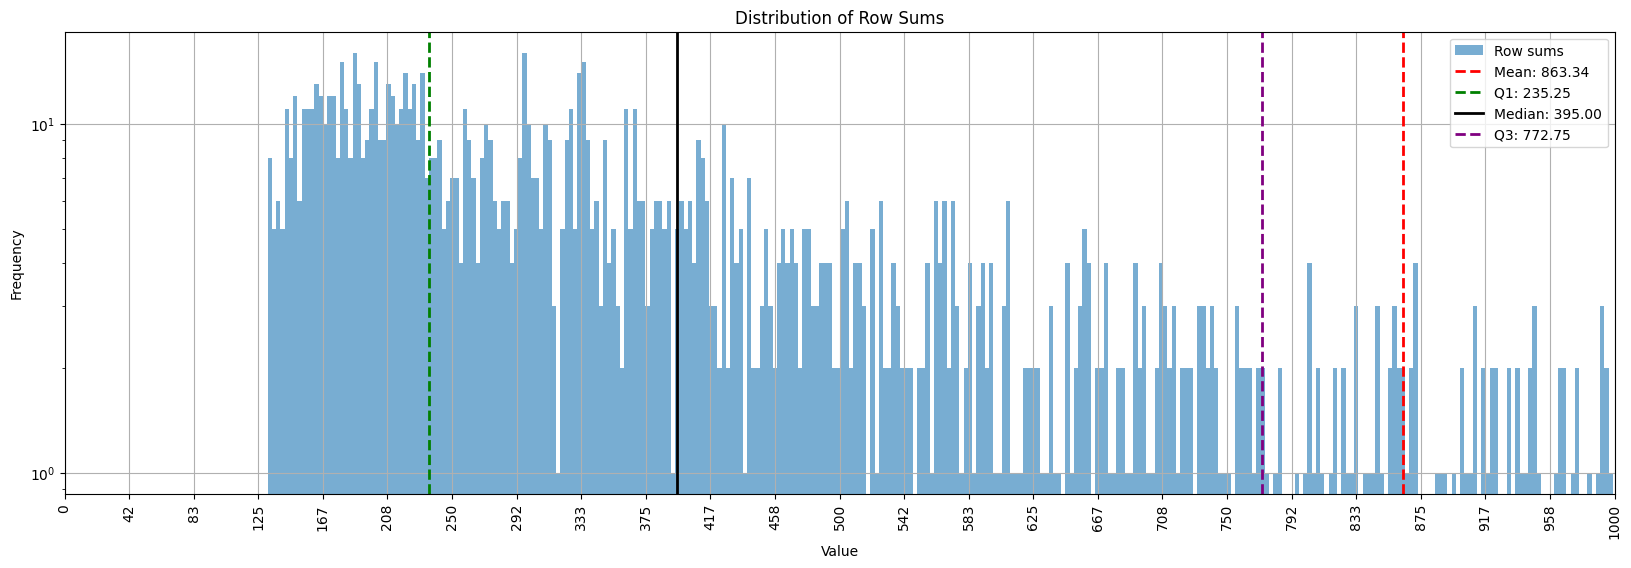

In [5]:
import matplotlib.pyplot as plt
import numpy as np

data = prot_non_norm_filtered_50

# Calculate total counts (sum) per row
row_sums = data.sum(axis=1)

# Calculate average count per row
row_means = data.mean(axis=1)

avg_row_sum = row_sums.mean()

# Quartiles
q1 = row_sums.quantile(0.25)
median = row_sums.quantile(0.5)
q3 = row_sums.quantile(0.75)

plt.figure(figsize=(20, 6))
plt.hist(row_sums, bins=10000, alpha=0.6, label='Row sums')

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of Row Sums")

plt.yscale('log')

plt.xlim(0, 1000)
plt.xticks(np.linspace(0, 1000, 25), rotation=90)

# Mean
plt.axvline(avg_row_sum, color='red', linestyle='--', linewidth=2,
            label=f'Mean: {avg_row_sum:.2f}')

# Quartiles
plt.axvline(q1, color='green', linestyle='--', linewidth=2,
            label=f'Q1: {q1:.2f}')
plt.axvline(median, color='black', linestyle='-', linewidth=2,
            label=f'Median: {median:.2f}')
plt.axvline(q3, color='purple', linestyle='--', linewidth=2,
            label=f'Q3: {q3:.2f}')

plt.legend()
plt.grid(True)
plt.show()

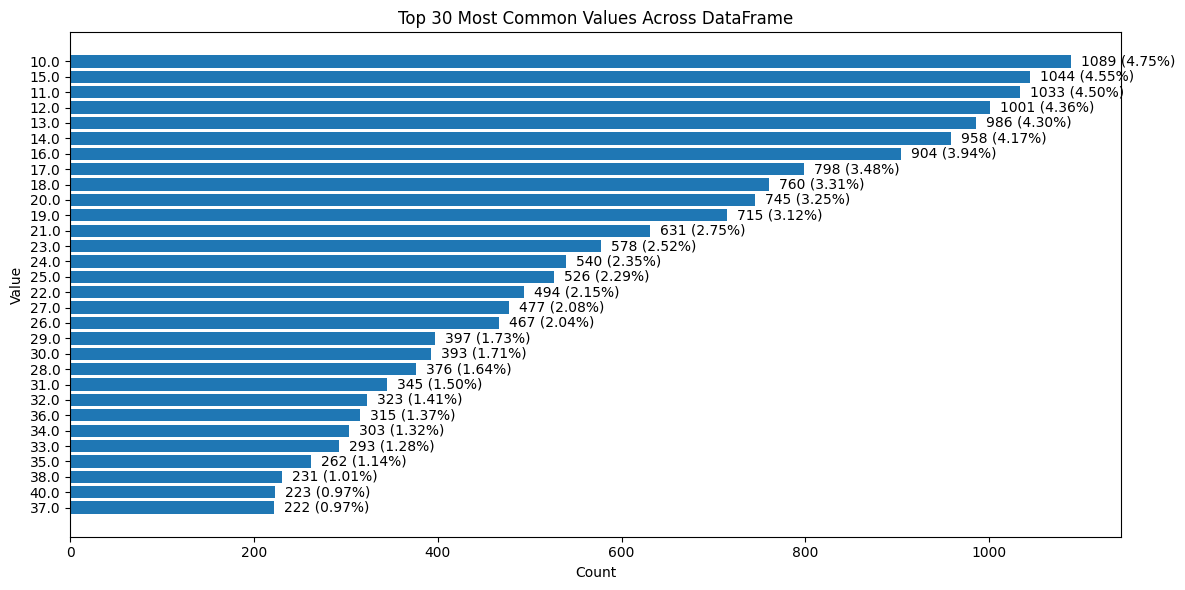

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure DataFrame
data = pd.DataFrame(prot_non_norm_filtered_50_above_10)

# Flatten ALL dataframe values into 1D array
all_values = pd.Series(data.to_numpy().ravel())

# Remove NaNs
all_values = all_values.dropna()

# Convert to string (optional but safer for mixed types)
all_values = all_values.astype(str)

# Top 10 most common values
top_10 = all_values.value_counts().head(30)

# Percentages
percentages = (top_10 / len(all_values)) * 100

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    y=top_10.index,
    width=top_10.values
)

# Highest on top
ax.invert_yaxis()

# Labels on bars
for bar, count, pct in zip(bars, top_10.values, percentages.values):
    ax.text(
        x=bar.get_width() + max(top_10.values) * 0.01,
        y=bar.get_y() + bar.get_height() / 2,
        s=f"{count} ({pct:.2f}%)",
        va="center"
    )

# Titles and labels
ax.set_xlabel("Count")
ax.set_ylabel("Value")
ax.set_title("Top 30 Most Common Values Across DataFrame")

plt.tight_layout()
plt.show()

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load Excel file
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_non_norm_filtered_50.xlsx"

df = pd.read_excel(
    path,
    index_col=0,
    header=[0,1,2,3,4]
)

# Output folder
output_folder = r"C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation\no_labels"
os.makedirs(output_folder, exist_ok=True)

# Convert to numeric
numeric_df = df.apply(pd.to_numeric, errors="coerce")

for gene, row in numeric_df.iterrows():

    values = row.dropna().values
    x = np.arange(len(values))

    mean = values.mean()
    std = values.std()

    fig, ax = plt.subplots(figsize=(10,4))

    # plot values
    ax.plot(x, values, marker="o")

    # mean line
    ax.axhline(mean)

    # ±1 SD band
    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.2
    )

    ax.set_title(f"{gene} (mean ± 1 SD)")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Abundance")

    plt.tight_layout()

    safe_gene = str(gene).replace("/", "_").replace("\\", "_")
    save_path = os.path.join(output_folder, f"{safe_gene}_std_band.png")

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()

print("Finished generating SD band plots.")

Finished generating SD band plots.


In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load Excel file
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_non_norm_filtered_50.xlsx"

df = pd.read_excel(
    path,
    index_col=0,
    header=[0,1,2,3,4]
)

# Output folder
output_folder = r"C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation"
os.makedirs(output_folder, exist_ok=True)

# Convert to numeric
numeric_df = df.apply(pd.to_numeric, errors="coerce")

for gene, row in numeric_df.iterrows():

    # Keep only non-NaN values
    valid = row.dropna()

    values = valid.values
    x = np.arange(len(values))

    # Create sample labels from MultiIndex columns
    labels = [
        " | ".join([str(v) for v in col if pd.notna(v)])
        for col in valid.index
    ]

    mean = values.mean()
    std = values.std()

    fig, ax = plt.subplots(figsize=(14,10))

    # Plot values
    ax.plot(x, values, marker="o")

    # Mean line
    ax.axhline(
        mean,
        linestyle="--",
        linewidth=1.5,
        label=f"Mean = {mean:.2f}"
    )

    # ±1 SD band
    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.2,
        label=f"±1 SD = {std:.2f}"
    )

    # Show sample labels on x-axis
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=7)

    # Keep normal y-axis values AND explicitly include mean value
    yticks = list(ax.get_yticks())

    # Add mean value if not already present
    if mean not in yticks:
        yticks.append(mean)

    yticks = sorted(yticks)

    ax.set_yticks(yticks)

    # Format y tick labels
    ytick_labels = [
        f"{tick:.2f}" if np.isclose(tick, mean) else f"{tick:.1f}"
        for tick in yticks
    ]

    ax.set_yticklabels(ytick_labels)

    ax.set_title(f"{gene} (mean ± 1 SD)")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Abundance")

    ax.legend()

    plt.tight_layout()

    safe_gene = str(gene).replace("/", "_").replace("\\", "_")
    save_path = os.path.join(output_folder, f"{safe_gene}_std_band.png")

    plt.savefig(save_path, dpi=600, bbox_inches="tight")
    plt.close()

print("Finished generating SD band plots with labels.")

Finished generating SD band plots with labels.


In [ ]:
import os
import pandas as pd
import numpy as np

# Load Excel file
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_non_norm_filtered_50.xlsx"

df = pd.read_excel(
    path,
    index_col=0,
    header=[0,1,2,3,4]
)

# Output folder
output_folder = r"C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation"
os.makedirs(output_folder, exist_ok=True)

# Convert to numeric
numeric_df = df.apply(pd.to_numeric, errors="coerce")

# Store results
results = []

for gene, row in numeric_df.iterrows():

    # Remove NaN values
    valid = row.dropna()

    values = valid.values

    # Create readable sample labels
    labels = [
        " | ".join([str(v) for v in col if pd.notna(v)])
        for col in valid.index
    ]

    mean = values.mean()
    std = values.std()

    upper_limit = mean + std
    lower_limit = mean - std

    # Check each sample
    for sample, value in zip(labels, values):

        if value > upper_limit:
            results.append({
                "Gene": gene,
                "Sample": sample,
                "Value": value,
                "Mean": mean,
                "Std": std,
                "Threshold": upper_limit,
                "Status": "Above +1 SD"
            })

        elif value < lower_limit:
            results.append({
                "Gene": gene,
                "Sample": sample,
                "Value": value,
                "Mean": mean,
                "Std": std,
                "Threshold": lower_limit,
                "Status": "Below -1 SD"
            })

# Create summary dataframe
summary_df = pd.DataFrame(results)

# Save summary table
summary_path = os.path.join(
    output_folder,
    "genes_outside_standard_deviation.xlsx"
)

summary_df.to_excel(summary_path, index=False)

print("Finished generating summary table.")
print(f"Summary saved to:\n{summary_path}")

In [8]:
import os
import pandas as pd
import numpy as np

# Load Excel file
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_non_norm_filtered_50.xlsx"

df = pd.read_excel(
    path,
    index_col=0,
    header=[0,1,2,3,4]
)

# Output folder
output_folder = r"C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation"
os.makedirs(output_folder, exist_ok=True)

# Convert to numeric
numeric_df = df.apply(pd.to_numeric, errors="coerce")

# Dictionary to aggregate genes by condition/sample
condition_summary = {}

for gene, row in numeric_df.iterrows():

    # Remove NaN values
    valid = row.dropna()

    values = valid.values

    # Create readable sample labels
    labels = [
        " | ".join([str(v) for v in col if pd.notna(v)])
        for col in valid.index
    ]

    mean = values.mean()
    std = values.std()

    upper_limit = mean + std
    lower_limit = mean - std

    # Check each sample/condition
    for sample, value in zip(labels, values):

        # Initialize condition if needed
        if sample not in condition_summary:
            condition_summary[sample] = {
                "Above +1 SD": [],
                "Below -1 SD": []
            }

        # Aggregate genes under each condition
        if value > upper_limit:
            condition_summary[sample]["Above +1 SD"].append(gene)

        elif value < lower_limit:
            condition_summary[sample]["Below -1 SD"].append(gene)

# Convert aggregated results into dataframe
rows = []

for sample, categories in condition_summary.items():

    rows.append({
        "Condition/Sample": sample,
        "Genes Above +1 SD": "; ".join(map(str, categories["Above +1 SD"])),
        "N Above +1 SD": len(categories["Above +1 SD"]),
        "Genes Below -1 SD": "; ".join(map(str, categories["Below -1 SD"])),
        "N Below -1 SD": len(categories["Below -1 SD"])
    })

summary_df = pd.DataFrame(rows)

# Save output
summary_path = os.path.join(
    output_folder,
    "genes_aggregated_by_condition.xlsx"
)

summary_df.to_excel(summary_path, index=False)

print("Finished generating aggregated summary.")
print(f"Summary saved to:\n{summary_path}")

Finished generating aggregated summary.
Summary saved to:
C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation\genes_aggregated_by_condition.xlsx


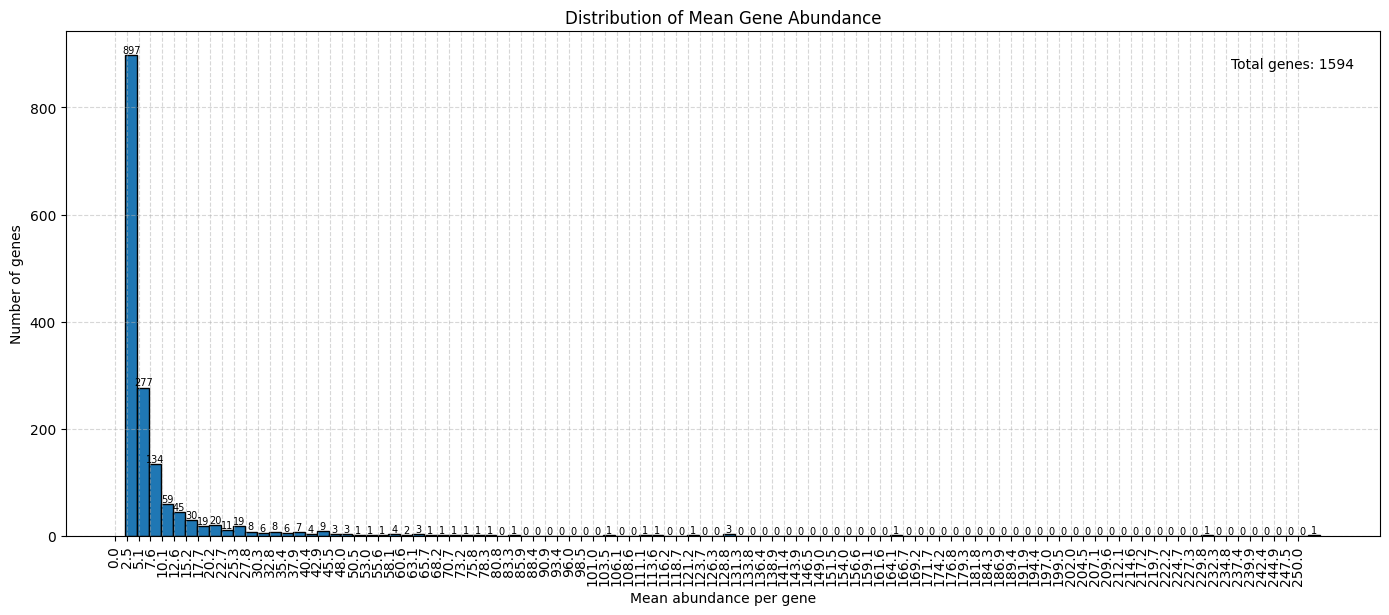

Distribution plot saved to:
C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation\gene_mean_abundance_distribution.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(14,6))

# Histogram
counts, bins, patches = ax.hist(
    gene_means.dropna(),
    bins=100,
    edgecolor="black"
)

# Add count labels above each bar
for count, patch in zip(counts, patches):
    x = patch.get_x() + patch.get_width() / 2
    y = patch.get_height()

    ax.text(
        x, y,
        f"{int(count)}",
        ha="center",
        va="bottom",
        fontsize=7
    )

ax.set_title("Distribution of Mean Gene Abundance")
ax.set_xlabel("Mean abundance per gene")
ax.set_ylabel("Number of genes")

ax.grid(True, linestyle="--", alpha=0.5)

# Total count annotation
ax.text(
    0.98, 0.95,
    f"Total genes: {len(gene_means.dropna())}",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

plt.tight_layout()

plot_path = os.path.join(
    output_folder,
    "gene_mean_abundance_distribution.png"
)

#Reference Lines
ax.axvline(mean_sd, linestyle='-', label=f"Mean = {mean_sd:.3f}")
ax.axvline(mean_sd - sd_sd, linestyle='--', label=f"Mean - 1 SD = {mean_sd - sd_sd:.3f}")
ax.axvline(mean_sd + sd_sd, linestyle='--', label=f"Mean + 1 SD = {mean_sd + sd_sd:.3f}")


plt.xticks(np.linspace(0, 250, 100), rotation=90)
plt.show()
#plt.savefig(plot_path, dpi=300, bbox_inches="tight")
#plt.close()

print(f"Distribution plot saved to:\n{plot_path}")

In [ ]:
row_std[row_std > 50]

Cc05_g00760     56.905903
Cc00_g11300     62.959932
Cc00_g11330    213.545736
Cc07_g05350     95.394937
Cc06_g12080    175.711510
dtype: float64

In [39]:
# Filter genes with SD greater than the mean SD
high_sd = row_std[row_std > mean_sd]

# Convert to DataFrame
high_sd_df = high_sd.to_frame(name="standard_deviation")

# Save to file
save_path = os.path.join(output_folder, "genes_sd_above_mean.csv")
high_sd_df.to_csv(save_path)

print(f"File saved to:\n{save_path}")

File saved to:
C:\Users\papan\Desktop\Coffeomics\proteomics\standard_deviation\genes_sd_above_mean.csv


In [ ]:
#GO for genes above mean SD

In [ ]:
#Standart deviation por row. Z score por coluna. 
#Tirar média por row e se for mais baixo que x não considera.

Formar Pairwise Dataframes

In [2]:
import pandas as pd
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\data\prot_normalized_pydeseq2_manual_50_above_10.xlsx"
prot_normalized_filtered_50_above_10 = pd.read_excel(path, index_col=0)

In [88]:
import pandas as pd
path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_normalized_pydeseq2_manual_50atleast.xlsx"
prot_normalized_filtered_50 = pd.read_excel(path, index_col=0)

In [3]:
path = r"C:\Users\papan\Desktop\Coffeomics\sample_information.csv"
metadata = pd.read_csv(path, index_col=0)
metadata = metadata[metadata["Proteomic"]]
metadata = metadata.T
metadata = metadata.iloc[:4,:]
metadata

Sample_ID,7A,7B,7C,20B,20C,8A,9B,9C,9E,10A,...,49C,51A,51B,51C,52A,52C,52D,54B,54C,54D
Species,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,...,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora
Temperature,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,...,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C
CO2_ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,700ppm,...,380ppm,380ppm,380ppm,380ppm,700ppm,700ppm,700ppm,700ppm,700ppm,700ppm
Water_Stress,without,without,without,medium,medium,medium,severe,severe,severe,without,...,without,severe,severe,severe,without,without,without,severe,severe,severe


In [4]:
from collections import defaultdict

def build_contrast_groups(metadata):
    """
    Group sample IDs that share the same experimental descriptor.

    Returns
    -------
    dict
        {
            "descriptor": [sample_ids]
        }
    """

    contrast_dict = defaultdict(list)

    for sample_id in metadata.columns:

        descriptor = " | ".join([
            str(metadata.loc["Species", sample_id]),
            str(metadata.loc["Temperature", sample_id]),
            str(metadata.loc["CO2_ppm", sample_id]),
            str(metadata.loc["Water_Stress", sample_id]),
        ])

        contrast_dict[descriptor].append(sample_id)

    return dict(contrast_dict)

In [5]:
import json

contrast_groups = build_contrast_groups(metadata)

with open("contrast_groups.json", "w") as f:
    json.dump(contrast_groups, f, indent=2)


In [ ]:
from itertools import combinations

data = prot_normalized_filtered_50_above_10

# --------------------------------------------------
# Build groups from metadata
# --------------------------------------------------
contrast_groups = build_contrast_groups(metadata)

# Example:
# {
#   "condition_A": ['7A', '7B', '7C'],
#   "condition_B": ['20A', '20B', '20C'],
#   ...
# }

# --------------------------------------------------
# Keep only groups with exactly 3 samples
# --------------------------------------------------
valid_groups = {
    name: samples
    for name, samples in contrast_groups.items()
    if len(samples) == 3
}

# --------------------------------------------------
# Build unordered 3-vs-3 contrasts
# --------------------------------------------------
allowed_contrasts = {}

for (name1, samples1), (name2, samples2) in combinations(valid_groups.items(), 2):

    combined = samples1 + samples2

    # keep only columns existing in dataframe
    combined = [
        s for s in combined
        if s in data.columns
    ]

    # require full 6-column contrast
    if len(combined) != 6:
        continue

    contrast_name = f"{name1} VS {name2}"

    allowed_contrasts[contrast_name] = combined

print(f"Total valid contrasts: {len(allowed_contrasts)}")

# --------------------------------------------------
# Analyze contrasts
# --------------------------------------------------
results = []
contrast_dfs = {}

for contrast_name, cols in allowed_contrasts.items():

    small_df = data[cols]
    contrast_dfs[contrast_name] = small_df

    nan_counts = small_df.isna().sum()

    max_nan_col = nan_counts.idxmax()
    max_nan_count = nan_counts.max()
    nan_pct = max_nan_count / len(small_df) * 100

    results.append({
        "contrast": contrast_name,
        "columns": cols,
        "n_cols": len(cols),
        "max_nan_col": max_nan_col,
        "max_nan_count": max_nan_count,
        "nan_pct": nan_pct
    })

# --------------------------------------------------
# Sort results
# --------------------------------------------------
results_sorted = sorted(
    results,
    key=lambda x: x["nan_pct"],
    reverse=True
)

# --------------------------------------------------
# Write report
# --------------------------------------------------
with open("combinations_report_above10.txt", "w") as f:

    f.write(f"Total valid contrasts: {len(allowed_contrasts)}\n\n")

    for r in results_sorted:

        f.write(
            f"{r['contrast']}\n"
            f"Columns: {', '.join(r['columns'])}\n"
            f"Max NaN: {r['max_nan_count']}/{len(data)} "
            f"in '{r['max_nan_col']}' "
            f"({r['nan_pct']:.2f}%)\n\n"
        )

Total valid contrasts: 630


In [96]:
from itertools import combinations
import os

data = prot_normalized_filtered_50
# --------------------------------------------------
# Create output folder
# --------------------------------------------------
output_folder = "small_dfs_filtered_normalized_atleast50"
os.makedirs(output_folder, exist_ok=True)

# --------------------------------------------------
# Build groups from metadata
# --------------------------------------------------
contrast_groups = build_contrast_groups(metadata)

# Example:
# {
#   "condition_A": ['7A', '7B', '7C'],
#   "condition_B": ['20A', '20B', '20C'],
# }

# --------------------------------------------------
# Keep only valid replicate groups (3 samples)
# --------------------------------------------------
valid_groups = {
    name: samples
    for name, samples in contrast_groups.items()
    if len(samples) == 3
}

# --------------------------------------------------
# Build unordered 3-vs-3 contrasts
# --------------------------------------------------
allowed_contrasts = {}

for (name1, samples1), (name2, samples2) in combinations(valid_groups.items(), 2):

    combined = samples1 + samples2

    # keep only columns existing in dataframe
    combined = [
        s for s in combined
        if s in data.columns
    ]

    # require full 6-column contrast
    if len(combined) != 6:
        continue

    contrast_name = (
        f"{name1}___VS___{name2}"
    )

    allowed_contrasts[contrast_name] = combined

# --------------------------------------------------
# Main loop
# --------------------------------------------------
results = {}
total_rows = len(data)

for contrast_name, selected_cols in allowed_contrasts.items():

    # Create small dataframe
    small_df = data[selected_cols]

    # Remove rows containing ANY NaN
    filtered_df = small_df.dropna()

    # --------------------------------------------------
    # Save dataframe
    # --------------------------------------------------
    safe_name = (
        contrast_name
        .replace("/", "_")
        .replace(" ", "_")
        .replace("|", "_")
        .replace(":", "_")
    )

    file_path = os.path.join(
        output_folder,
        f"small_df_{safe_name}.csv"
    )

    filtered_df.to_csv(file_path)

    # --------------------------------------------------
    # Statistics
    # --------------------------------------------------
    rows_after = len(filtered_df)
    rows_lost = total_rows - rows_after
    pct_lost = rows_lost / total_rows * 100

    lost_genes = small_df.index.difference(filtered_df.index)

    results[contrast_name] = {
        "columns": selected_cols,
        "n_cols": len(selected_cols),
        "rows_after": rows_after,
        "rows_lost": rows_lost,
        "pct_lost": pct_lost,
        "lost_genes": list(lost_genes)
    }

# --------------------------------------------------
# Sort results by percentage lost
# --------------------------------------------------
results_sorted = sorted(
    results.items(),
    key=lambda x: x[1]["pct_lost"],
    reverse=True
)

# --------------------------------------------------
# Write report
# --------------------------------------------------
with open("nan_row_filter_normalized_report_atleast50.txt", "w") as f:

    f.write(f"Total genes (rows): {total_rows}\n")
    f.write(f"Total valid contrasts: {len(allowed_contrasts)}\n\n")

    for contrast_name, r in results_sorted:

        f.write(
            f"{contrast_name}\n"
            f"Columns: {', '.join(r['columns'])}\n"
            f"Rows kept: {r['rows_after']}/{total_rows} | "
            f"Rows lost: {r['rows_lost']}/{total_rows} "
            f"({r['pct_lost']:.2f}%)\n"
        )

        f.write("Lost genes:\n")

        for gene in r["lost_genes"]:
            f.write(f"{gene}\n")

        f.write("\n" + "-" * 80 + "\n\n")

print(
    f"Saved {len(allowed_contrasts)} filtered dataframes "
    f"to '{output_folder}'"
)

print("Report saved to nan_row_filter_report_atleast50.txt")

Saved 630 filtered dataframes to 'small_dfs_filtered_normalized_atleast50'
Report saved to nan_row_filter_report_atleast50.txt


Add header and remove cross-species comparisons

In [97]:
# To label small dataframes while preserving gene IDs/indexes

import pandas as pd
from pathlib import Path

folder = Path(
    r"C:\Users\papan\Desktop\Coffeomics\proteomics\small_dfs_filtered_normalized_atleast50"
)

# Transpose once
df = metadata.copy()

# Force all indexes to string for safety
df.index = df.index.astype(str)

for file in folder.glob("*.csv"):

    # Preserve original gene IDs as index
    data = pd.read_csv(file, index_col=0)

    # Ensure index stays string
    data.index = data.index.astype(str)

    # Find common columns only
    common_cols = data.columns.intersection(df.columns)

    # Skip empty matches
    if len(common_cols) == 0:
        print(f"Skipping {file.name} (no common columns)")
        continue

    # Subset both dataframes
    top_part = df.loc[:, common_cols]
    data_part = data.loc[:, common_cols]

    # Preserve indexes during concatenation
    combined = pd.concat(
        [top_part, data_part],
        axis=0
    )

    # Save while explicitly preserving index label
    combined.to_csv(file, index_label="ID")

    print(f"Saved: {file.name}")

Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___380ppm___severe.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___700ppm___medium.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___700ppm___severe.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___700ppm___without.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___380ppm___severe.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___380ppm___without.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___700ppm___severe.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___700ppm___without.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___42_30°C___380ppm___severe.csv
Saved: small_df_C._arabica___25_20°C___380ppm___medi

In [98]:
#To eliminate small dataframes with both species
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\papan\Desktop\Coffeomics\proteomics\small_dfs_filtered_normalized_atleast50")

for file in folder.glob("*.csv"):
    
    df = pd.read_csv(file, index_col=0)
    
    if "Species" not in df.index:
        continue
    
    species_values = df.loc["Species"].astype(str)
    
    if ("C. arabica" in species_values.values) and ("C. canephora" in species_values.values):
        file.unlink()  # delete file
        print(f"Deleted: {file.name}")

Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___25_20°C___380ppm___medium.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___25_20°C___380ppm___severe.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___25_20°C___380ppm___without.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___25_20°C___700ppm___medium.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___25_20°C___700ppm___severe.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___25_20°C___700ppm___without.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___37_28°C___380ppm___severe.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___37_28°C___380ppm___without.csv
Deleted: small_df_C._arabica___25_20°C___380ppm___medium___VS___C._canephora___37_28°C___700ppm___severe.csv
Deleted: small_d

Correlação Pearson Pairwise Construção Matriz

In [73]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# --------------------------------------------------
# Folder
# --------------------------------------------------
folder = Path(
    r"C:\Users\papan\Desktop\Coffeomics\proteomics\small_dfs_filtered_non_normalized_above_10"
)

# --------------------------------------------------
# Output folder
# --------------------------------------------------
output_folder = folder / "global_sample_clustermaps_above_10"
output_folder.mkdir(exist_ok=True)

# --------------------------------------------------
# Sample -> species mapping
# --------------------------------------------------
sample_to_species = metadata.loc["Species"].to_dict()

# --------------------------------------------------
# Containers
# --------------------------------------------------
species_pairwise = {
    "C_arabica": {},
    "C_canephora": {}
}

species_counts = {
    "C_arabica": {},
    "C_canephora": {}
}

# --------------------------------------------------
# Process each local comparison independently
# --------------------------------------------------
all_files = list(folder.rglob("*.csv"))

print(f"Found {len(all_files)} files\n")

for i, file in enumerate(all_files, start=1):

    print(f"[{i}/{len(all_files)}] {file.name}")

    try:

        # --------------------------------------------------
        # Load local dataframe
        # --------------------------------------------------
        df = pd.read_csv(file, index_col=0)

        df = df.apply(pd.to_numeric, errors="coerce")
        df = df.dropna()

        if df.shape[1] != 6:
            continue

        samples = list(df.columns)

        # --------------------------------------------------
        # Infer species from samples
        # --------------------------------------------------
        species_set = {
            sample_to_species.get(sample)
            for sample in samples
        }

        species_set.discard(None)

        if len(species_set) != 1:
            continue

        species = list(species_set)[0]

        if "arabica" in species.lower():
            species_key = "C_arabica"

        elif "canephora" in species.lower():
            species_key = "C_canephora"

        else:
            continue

        # --------------------------------------------------
        # Local Pearson correlation
        # --------------------------------------------------
        corr = df.corr(method="pearson")

        # --------------------------------------------------
        # Accumulate correlations globally
        # --------------------------------------------------
        for s1 in corr.index:
            for s2 in corr.columns:

                pair = tuple(sorted([s1, s2]))

                value = corr.loc[s1, s2]

                if np.isnan(value):
                    continue

                if pair not in species_pairwise[species_key]:
                    species_pairwise[species_key][pair] = 0
                    species_counts[species_key][pair] = 0

                species_pairwise[species_key][pair] += value
                species_counts[species_key][pair] += 1

    except Exception as e:

        print(f"Error with {file.name}: {e}")

# --------------------------------------------------
# Build final matrices
# --------------------------------------------------
for species_key in species_pairwise.keys():

    print(f"\nBuilding final matrix for {species_key}")

    pairs = species_pairwise[species_key]

    # --------------------------------------------------
    # All samples
    # --------------------------------------------------
    samples = sorted({
        s
        for pair in pairs.keys()
        for s in pair
    })

    # --------------------------------------------------
    # Empty matrix
    # --------------------------------------------------
    matrix = pd.DataFrame(
        np.nan,
        index=samples,
        columns=samples
    )

    # --------------------------------------------------
    # Fill averaged correlations
    # --------------------------------------------------
    for pair, total_corr in pairs.items():

        avg_corr = (
            total_corr /
            species_counts[species_key][pair]
        )

        s1, s2 = pair

        matrix.loc[s1, s2] = avg_corr
        matrix.loc[s2, s1] = avg_corr

    # diagonal = 1
    np.fill_diagonal(matrix.values, 1)

    # fill remaining NaNs with 0
    matrix = matrix.fillna(0)

    # --------------------------------------------------
    # Clustering
    # --------------------------------------------------
    distance_matrix = 1 - matrix

    linkage_matrix = linkage(
        squareform(distance_matrix),
        method="average"
    )

    # --------------------------------------------------
    # Save dendrogram separately
    # --------------------------------------------------
    plt.figure(figsize=(20, 10))

    dendrogram(
        linkage_matrix,
        labels=matrix.index,
        leaf_rotation=90,
        leaf_font_size=6
    )

    plt.title(
        f"{species_key} Pearson Correlation Tree"
    )

    plt.tight_layout()

    tree_path = output_folder / (
        f"{species_key}_tree.png"
    )

    plt.savefig(
        tree_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # --------------------------------------------------
    # Final clustermap
    # --------------------------------------------------
    clustergrid = sns.clustermap(
        matrix,
        row_linkage=linkage_matrix,
        col_linkage=linkage_matrix,
        cmap="PuOr",
        center=0,
        figsize=(28, 28),
        linewidths=0.5,
        annot=True,
        fmt=".2f",
        annot_kws={
            "color": "white",
            "fontsize": 5
        }
    )

    clustergrid.fig.suptitle(
        f"{species_key} Global Pearson Clustermap",
        y=1.02
    )

    heatmap_path = output_folder / (
        f"{species_key}_clustermap.png"
    )

    clustergrid.savefig(
        heatmap_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(f"Saved:")
    print(heatmap_path)
    print(tree_path)

print("\nFinished.")

Found 306 files

[1/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___380ppm___severe.csv
[2/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___700ppm___medium.csv
[3/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___700ppm___severe.csv
[4/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___25_20°C___700ppm___without.csv
[5/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___380ppm___severe.csv
[6/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___380ppm___without.csv
[7/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___700ppm___severe.csv
[8/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___37_28°C___700ppm___without.csv
[9/306] small_df_C._arabica___25_20°C___380ppm___medium___VS___C._arabica___42_30°C___380ppm___severe.csv
[10/306] small_df_C._arabi

Normalização Manual

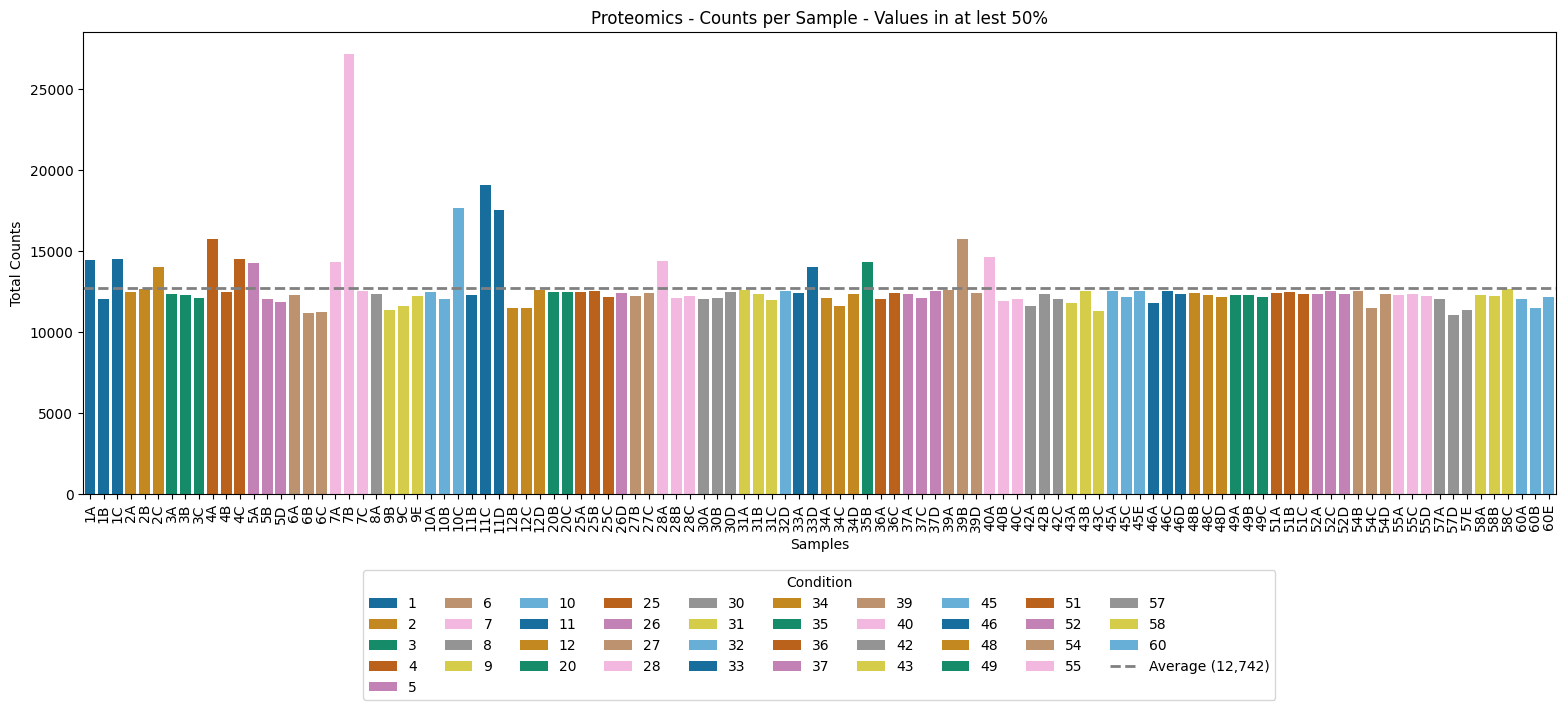

In [71]:
# With values below 10
import sys
sys.path.append(r"C:\Users\papan\Desktop\Coffeomics")

from data_characterization import to_bar_graph_counts_per_sample
to_bar_graph_counts_per_sample(prot_non_norm_filtered_50, f"Proteomics - Counts per Sample - Values in at lest 50%", average=True, sorted=True)


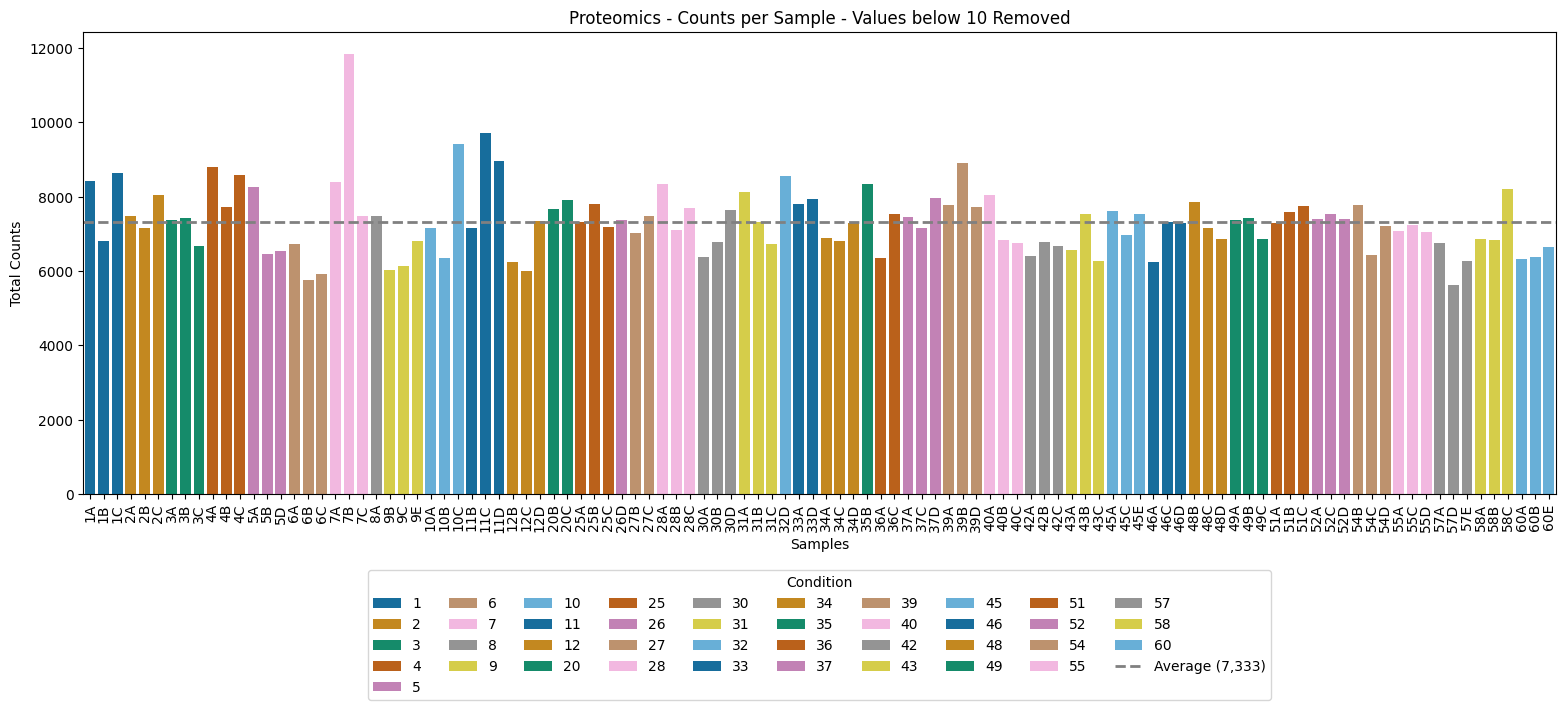

In [69]:
#Values below 10 removed

import sys
sys.path.append(r"C:\Users\papan\Desktop\Coffeomics")

from data_characterization import to_bar_graph_counts_per_sample
to_bar_graph_counts_per_sample(prot_non_norm_filtered_50_above_10, f"Proteomics - Counts per Sample - Values below 10 Removed", average=True, sorted=True)

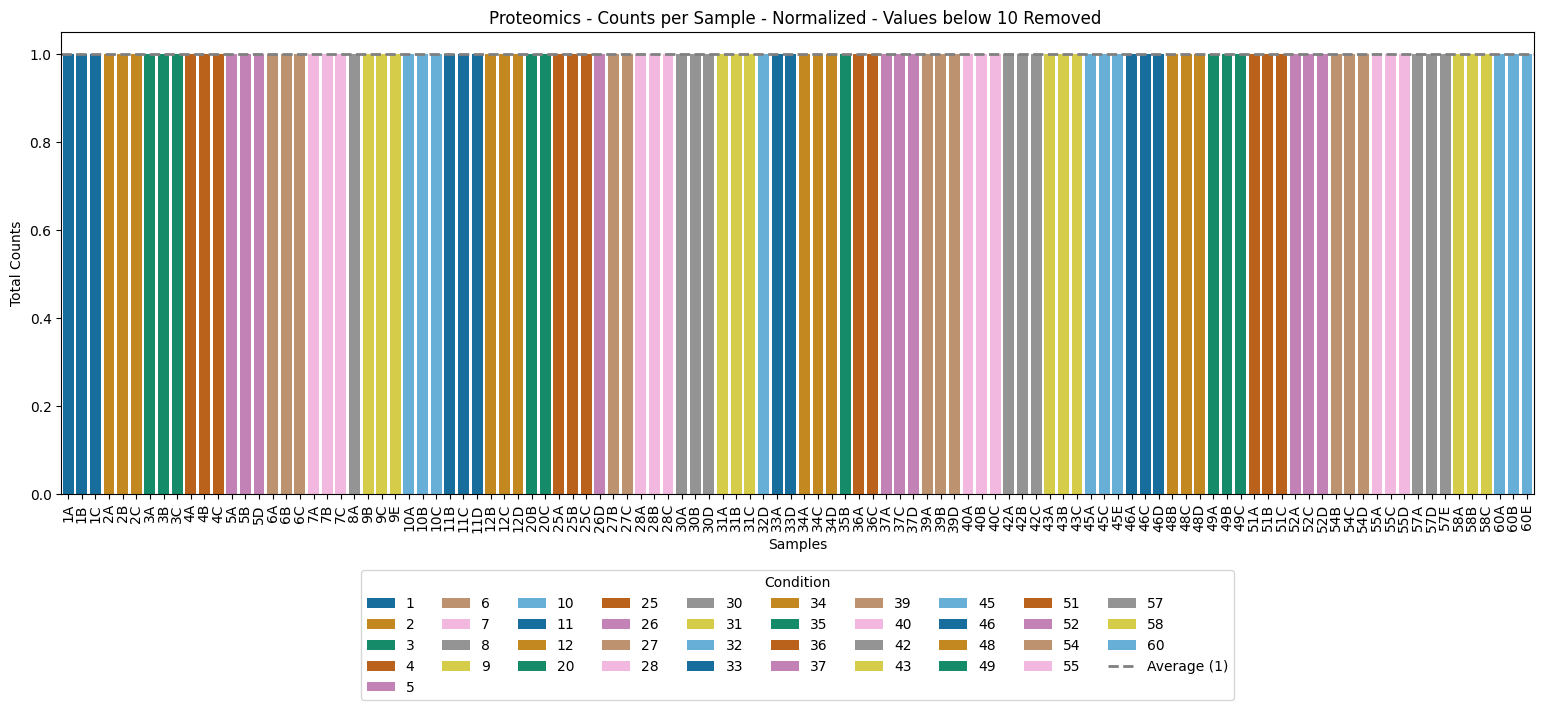

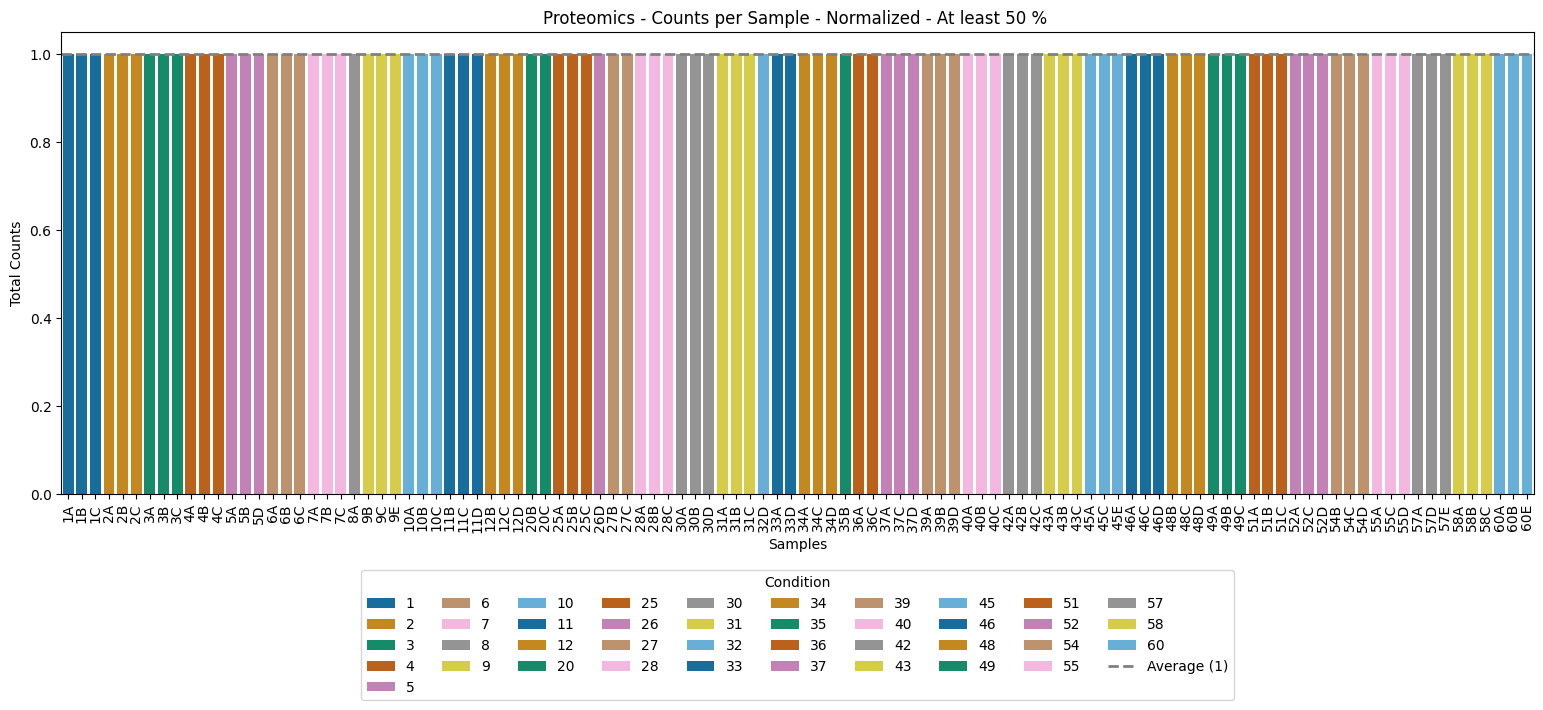

In [75]:

from data_normalization import manual_normalization, pydeseq2_normalization
from scipy.stats import gmean

#size normalization first
#Tirar genes

def pydese2_manual_normalization(count_data):
    geo_means = gmean(count_data, axis=1) # dseq drop all-zero genes from the mean 
    ratio = count_data.divide(geo_means, axis=0)
    size_factor=ratio.median(axis=0) 
    normalization=manual_normalization(count_data, size_factor)
    return normalization

import numpy as np
from scipy.stats import gmean

def pydese2_manual_normalization_options(count_data, size_method="sum"):
    """
    count_data: pandas DataFrame (proteins x samples)
    normalize_by_size: if False, skips size factor normalization
    size_method: 
        - "sum"  -> column sum normalization
        - "non_nan_count" -> number of detected proteins per sample
        - "median_ratio" -> DESeq2-style (recommended default)
    """

    if size_method == "median_ratio":
        # DESeq2-style (recommended baseline)
        geo_means = gmean(count_data.replace(0, np.nan), axis=1, nan_policy='omit')
        ratio = count_data.div(geo_means, axis=0)
        size_factor = ratio.median(axis=0, skipna=True)

    elif size_method == "sum":
        # total intensity per sample
        size_factor = count_data.sum(axis=0, skipna=True)

    elif size_method == "non_nan_count":
        # proteome coverage per sample
        size_factor = count_data.notna().sum(axis=0)

    else:
        raise ValueError("size_method must be 'median_ratio', 'sum', or 'non_nan_count'")

    # avoid division issues
    size_factor = size_factor.replace(0, np.nan)

    normalized = count_data.div(size_factor, axis=1)

    return normalized

data = prot_non_norm_filtered_50_above_10
data_normalization = pydese2_manual_normalization_options(data, size_method = "sum")
#data_normalization.to_excel("prot_normalized_pydeseq2_manual_50_above_10.xlsx")

to_bar_graph_counts_per_sample(data_normalization, f"Proteomics - Counts per Sample - Normalized - Values below 10 Removed ", average=True, sorted=True)

data = prot_non_norm_filtered_50
data_normalization = pydese2_manual_normalization_options(data, size_method = "sum")
#data_normalization.to_excel("prot_normalized_pydeseq2_manual_50atleast.xlsx")

to_bar_graph_counts_per_sample(data_normalization, f"Proteomics - Counts per Sample - Normalized - At least 50 % ", average=True, sorted=True)


Analíse df pequeno

In [8]:
total = data.size
num_zeros = (data == 0).sum().sum()
num_nan = data.isna().sum().sum()

print(f"Number of 0s: {num_zeros}/{total} ({num_zeros/total*100:.2f}%)")
print(f"Number of NaNs: {num_nan}/{total} ({num_nan/total*100:.2f}%)")

Number of 0s: 0/128250 (0.00%)
Number of NaNs: 21222/128250 (16.55%)


In [9]:
import pandas as pd

# Compute metrics
row_sums = data.sum(axis=1)
row_means = data.mean(axis=1)

# Count columns that actually contain values (exclude NaN)
row_non_nan_counts = data.notna().sum(axis=1)

# Build analysis table for all rows
analysis = pd.DataFrame({
    "total_expression": row_sums,
    "average_expression": row_means,
    "num_columns_with_entries": row_non_nan_counts
})

# Sort by total expression
analysis = analysis.sort_values("total_expression", ascending=False)

excel_file_path = r"C:\Users\papan\Desktop\Coffeomics\proteomics\raw data partitioned\non_continuous_columns_50_percent.xlsx"

# Save to Excel
with pd.ExcelWriter(excel_file_path) as writer:
    data.to_excel(writer, sheet_name="prot_raw_data")
    analysis.to_excel(writer, sheet_name="analysis")

Gerar todas dataframes pequenos

In [ ]:
from itertools import combinations
import re

data = data_normalization

# Extract numeric part from column names
numbers = sorted({
    re.match(r"\d+", col).group()
    for col in data.columns
})

all_combinations = list(combinations(numbers, 2))

results = []
combination_dfs = {}

for comb in all_combinations:
    selected_cols = [
        col for col in data.columns
        if re.match(r"\d+", col).group() in comb
    ]

    small_df = data[selected_cols]
    combination_dfs[comb] = small_df

    nan_counts = small_df.isna().sum()
    max_nan_col = nan_counts.idxmax()
    max_nan_count = nan_counts.max()
    nan_pct = max_nan_count / len(small_df) * 100

    results.append({
        "combination": comb,
        "n_cols": len(selected_cols),
        "max_nan_col": max_nan_col,
        "max_nan_count": max_nan_count,
        "nan_pct": nan_pct
    })

# Sort by percentage of missing values (ascending or descending)
results_sorted = sorted(results, key=lambda x: x["nan_pct"], reverse=True)

# Write report
with open("combinations_report.txt", "w") as f:
    f.write(f"Found {len(numbers)} unique numbers\n")
    f.write(f"Total combinations: {len(all_combinations)}\n\n")

    for r in results_sorted:
        f.write(
            f"Combination {r['combination']}: {r['n_cols']} columns | "
            f"Max NaN: {r['max_nan_count']}/{len(data)} "
            f"in '{r['max_nan_col']}' ({r['nan_pct']:.2f}%)\n"
        )


NameError: name 'data_normalization' is not defined

In [13]:
from itertools import combinations

pairs = list(combinations(numbers, 2))

print(len(pairs))  # 703

703


In [14]:
from itertools import combinations
import re
import os

# Create output folder
output_folder = "small_dfs_normalized"
os.makedirs(output_folder, exist_ok=True)

# Precompute numeric prefixes once
col_number_map = {}
for col in data.columns:
    match = re.match(r"\d+", col)
    if match:
        col_number_map[col] = match.group()

numbers = sorted(set(col_number_map.values()))
all_combinations = list(combinations(numbers, 2))

results = {}
total_rows = len(data)

for comb in all_combinations:

    selected_cols = [
        col for col, num in col_number_map.items()
        if num in comb
    ]

    small_df = data[selected_cols]

    # Remove rows with at least one NaN
    filtered_df = small_df.dropna()

    # Save dataframe immediately
    comb_name = f"{comb[0]}_{comb[1]}"
    file_path = os.path.join(output_folder, f"small_df_{comb_name}.csv")
    filtered_df.to_csv(file_path)

    rows_after = len(filtered_df)
    rows_lost = total_rows - rows_after
    pct_lost = rows_lost / total_rows * 100

    lost_genes = small_df.index.difference(filtered_df.index)

    results[comb] = {
        "n_cols": len(selected_cols),
        "rows_after": rows_after,
        "rows_lost": rows_lost,
        "pct_lost": pct_lost,
        "lost_genes": list(lost_genes)
    }

# Sort results by % lost
results_sorted = sorted(results.items(), key=lambda x: x[1]["pct_lost"], reverse=True)

# Write report
with open("nan_row_filter_report.txt", "w") as f:

    f.write(f"Total genes (rows): {total_rows}\n")
    f.write(f"Total combinations: {len(all_combinations)}\n\n")

    for comb, r in results_sorted:

        f.write(
            f"Combination {comb} | "
            f"Columns: {r['n_cols']} | "
            f"Rows kept: {r['rows_after']}/{total_rows} | "
            f"Rows lost: {r['rows_lost']}/{total_rows} ({r['pct_lost']:.2f}%)\n"
        )

        f.write("Lost genes:\n")

        for gene in r["lost_genes"]:
            f.write(f"{gene}\n")

        f.write("\n" + "-"*60 + "\n\n")

print(f"Saved {len(all_combinations)} filtered dataframes to '{output_folder}'")
print("Report saved to nan_row_filter_report.txt")

Saved 703 filtered dataframes to 'small_dfs_normalized'
Report saved to nan_row_filter_report.txt
